# Customer Churn Prediction with an Artificial Neural Network

This notebook prepares customer data and trains a binary classification model to predict whether a bank customer will leave (`Exited = 1`).

## 1. Import libraries

In [140]:
import numpy as np
import pandas as pd

## 2. Load and inspect the dataset

Load the churn data, preview the first rows, and inspect its structure and basic category distributions.

In [141]:
df = pd.read_csv('Churn_Modelling.csv')

In [142]:
df.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


## 3. Initial data inspection

The identifier columns (`RowNumber`, `CustomerId`, and `Surname`) do not describe customer behavior, so they will not be used as model features. The checks below also inspect data types, duplicates, the target balance, and categorical values.

In [143]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  str    
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  str    
 5   Gender           10000 non-null  str    
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), str(3)
memory usage: 1.2 MB


In [144]:
df.duplicated().sum()

np.int64(0)

In [145]:
df['Exited'].value_counts()

Exited
0    7963
1    2037
Name: count, dtype: int64

In [146]:
df['Geography'].value_counts()

Geography
France     5014
Germany    2509
Spain      2477
Name: count, dtype: int64

In [147]:
df['Gender'].value_counts()

Gender
Male      5457
Female    4543
Name: count, dtype: int64

## 4. Clean the feature columns

Remove the identifier fields before modeling, then preview the remaining customer features.

In [148]:
df.drop(columns=['RowNumber', 'CustomerId', 'Surname'],inplace= True)

In [149]:
df.head()

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


## 5. Encode categorical features

Convert `Geography` and `Gender` into numeric dummy variables. `drop_first=True` avoids redundant columns, which leaves 11 input features for the neural network.

In [150]:
df = pd.get_dummies(
    df,
    columns=['Geography', 'Gender'],
    drop_first=True,
    dtype=int
)
df.head()

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Geography_Germany,Geography_Spain,Gender_Male
0,619,42,2,0.00,1,1,1,101348.88,1,0,0,0
1,608,41,1,83807.86,1,0,1,112542.58,0,0,1,0
2,502,42,8,159660.80,3,1,0,113931.57,1,0,0,0
3,699,39,1,0.00,2,0,0,93826.63,0,0,0,0
4,850,43,2,125510.82,1,1,1,79084.10,0,0,1,0


## 6. Prepare the training and test sets

Separate the predictors (`X`) from the target (`y`), then split the data so the model can be evaluated on unseen customers.

In [151]:
X = df.drop(columns=['Exited'])
y = df['Exited']
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=1, stratify=y
)
X_train, X_val, y_train, y_val = train_test_split(
    X_train, y_train, test_size=0.2, random_state=1, stratify=y_train
)

In [152]:
X

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Geography_Germany,Geography_Spain,Gender_Male
0,619,42,2,0.00,1,1,1,101348.88,0,0,0
1,608,41,1,83807.86,1,0,1,112542.58,0,1,0
2,502,42,8,159660.80,3,1,0,113931.57,0,0,0
3,699,39,1,0.00,2,0,0,93826.63,0,0,0
4,850,43,2,125510.82,1,1,1,79084.10,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...
9995,771,39,5,0.00,2,1,0,96270.64,0,0,1
9996,516,35,10,57369.61,1,1,1,101699.77,0,0,1
9997,709,36,7,0.00,1,0,1,42085.58,0,0,0
9998,772,42,3,75075.31,2,1,0,92888.52,1,0,1


In [153]:
y

0       1
1       0
2       1
3       0
4       0
       ..
9995    0
9996    0
9997    1
9998    1
9999    0
Name: Exited, Length: 10000, dtype: int64

In [154]:
X_train

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Geography_Germany,Geography_Spain,Gender_Male
2694,628,29,3,113146.98,2,0,1,124749.08,1,0,1
5140,626,29,4,105767.28,2,0,0,41104.82,0,0,0
2568,612,47,6,130024.87,1,1,1,45750.21,1,0,0
3671,646,52,6,111739.40,2,0,1,68367.18,1,0,0
7427,714,33,8,122017.19,1,0,0,162515.17,0,1,1
...,...,...,...,...,...,...,...,...,...,...,...
2895,621,47,7,107363.29,1,1,1,66799.28,1,0,1
7813,684,63,3,81245.79,1,1,0,69643.31,1,0,0
905,672,45,9,0.00,1,1,1,92027.69,0,0,0
5192,663,39,8,0.00,2,1,1,101168.90,0,0,0


In [155]:
X_test

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Geography_Germany,Geography_Spain,Gender_Male
9953,550,47,2,0.00,2,1,1,97057.28,0,0,1
3850,680,34,3,143292.95,1,1,0,66526.01,0,0,1
4962,531,42,2,0.00,2,0,1,90537.47,0,0,0
3886,710,34,8,147833.30,2,0,1,1561.58,1,0,1
5437,543,30,6,73481.05,1,1,1,176692.65,1,0,1
...,...,...,...,...,...,...,...,...,...,...,...
3919,763,39,7,0.00,2,1,0,19458.75,0,1,0
162,800,49,7,108007.36,1,0,0,47125.11,0,0,0
7903,567,34,10,0.00,2,0,1,161571.79,0,1,1
2242,621,30,2,101014.08,2,1,1,165257.31,1,0,0


In [156]:
X_train.shape

(8000, 11)

In [157]:
X_test.shape

(2000, 11)

In [158]:
y_train.shape

(8000,)

In [159]:
y_test.shape

(2000,)

## 7. Scale the numeric features

Standardize the input features so they are on comparable scales. This helps the neural network optimize more reliably.

In [160]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

In [161]:
X_train

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Geography_Germany,Geography_Spain,Gender_Male
2694,628,29,3,113146.98,2,0,1,124749.08,1,0,1
5140,626,29,4,105767.28,2,0,0,41104.82,0,0,0
2568,612,47,6,130024.87,1,1,1,45750.21,1,0,0
3671,646,52,6,111739.40,2,0,1,68367.18,1,0,0
7427,714,33,8,122017.19,1,0,0,162515.17,0,1,1
...,...,...,...,...,...,...,...,...,...,...,...
2895,621,47,7,107363.29,1,1,1,66799.28,1,0,1
7813,684,63,3,81245.79,1,1,0,69643.31,1,0,0
905,672,45,9,0.00,1,1,1,92027.69,0,0,0
5192,663,39,8,0.00,2,1,1,101168.90,0,0,0


In [162]:
X_train_scaled

array([[-0.23082038, -0.94449979, -0.70174202, ...,  1.71490137,
        -0.57273139,  0.91509065],
       [-0.25150912, -0.94449979, -0.35520275, ..., -0.58312392,
        -0.57273139, -1.09278791],
       [-0.3963303 ,  0.77498705,  0.33787579, ...,  1.71490137,
        -0.57273139, -1.09278791],
       ...,
       [ 0.22433188,  0.58393295,  1.3774936 , ..., -0.58312392,
        -0.57273139, -1.09278791],
       [ 0.13123255,  0.01077067,  1.03095433, ..., -0.58312392,
        -0.57273139, -1.09278791],
       [ 1.1656695 ,  0.29735181,  0.33787579, ...,  1.71490137,
        -0.57273139,  0.91509065]], shape=(8000, 11))

## 8. Build the artificial neural network

Create a small feed-forward network with one hidden layer and a sigmoid output for binary churn prediction.

In [163]:
import tensorflow
from tensorflow import keras 
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Input 

In [164]:
model = Sequential([
    Input(shape=(X_train_scaled.shape[1],)),
    Dense(11, activation="relu"),
    Dense(11, activation="relu"),
    Dense(1, activation="sigmoid")
])

c:\New folder\Lib\site-packages\keras\src\layers\core\dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [165]:
model.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_11 (Dense)                │ (None, 11)             │           132 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 11)             │           132 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 1)              │            12 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 276 (1.08 KB)

 Trainable params: 276 (1.08 KB)

 Non-trainable params: 0 (0.00 B)

In [166]:
model.compile(loss = "binary_crossentropy"  , optimizer = "Adam" , metrics= ['accuracy'])

## 9. Train the model

Fit the network on the scaled training data for 100 epochs.

In [167]:
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.utils.class_weight import compute_class_weight

classes = np.unique(y_train)
weights = compute_class_weight(
    class_weight="balanced", classes=classes, y=y_train
)
class_weights = dict(zip(classes, weights))
USE_CLASS_WEIGHTS = False

early_stop = EarlyStopping(
    monitor="val_loss", patience=10, restore_best_weights=True
)

history = model.fit(
    X_train_scaled,
    y_train,
    epochs=200,
    validation_data=(X_val_scaled, y_val),
    callbacks=[early_stop],
    class_weight=class_weights if USE_CLASS_WEIGHTS else None
)

Epoch 1/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.6452 - loss: 0.6347 - val_accuracy: 0.7969 - val_loss: 0.4955
Epoch 2/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8002 - loss: 0.4754 - val_accuracy: 0.7950 - val_loss: 0.4554
Epoch 3/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7975 - loss: 0.4451 - val_accuracy: 0.7994 - val_loss: 0.4380
Epoch 4/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8082 - loss: 0.4416 - val_accuracy: 0.8031 - val_loss: 0.4276
Epoch 5/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8183 - loss: 0.4245 - val_accuracy: 0.8075 - val_loss: 0.4188
Epoch 6/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8198 - loss: 0.4178 - val_accuracy: 0.8094 - val_loss: 0.4088
Epoch 7/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8302 - loss: 0.3956 - val_accuracy: 0.8169 - val_loss: 0.4000
Epoch 8/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8300 - loss: 0.3956 - val_accu

In [168]:
model.layers[1].get_weights()

[array([[-0.23134531, -0.13016188, -0.21142405, -0.04971154,  0.3636149 ,
         -0.19746824, -0.03738969,  0.31725368, -0.466285  ,  0.34285334,
          0.37095755],
        [-0.08604268, -0.64601123, -0.36492926,  0.13847804, -0.35317153,
         -0.08257797,  0.48168015,  0.11609945, -0.01692557, -0.64664847,
          0.05111523],
        [ 0.16452299, -0.11744498, -0.70092386,  0.5600104 ,  0.6741849 ,
          0.0374926 , -0.34136942, -0.47536993,  0.13843164, -0.14545874,
          0.01990064],
        [-0.29624668, -0.6907762 , -0.18967935, -0.00179003,  0.43681273,
         -0.15839344, -1.1649921 , -0.57392174, -0.87055546,  0.5169802 ,
         -0.5220972 ],
        [ 0.02207292, -0.33156303,  0.38841778, -0.3159997 , -0.54630834,
          0.18533954, -0.17664449,  0.17558053,  0.05905714, -0.48976707,
         -0.6887101 ],
        [-0.5761509 ,  0.8364178 , -0.83309484,  0.63409775,  0.3878279 ,
         -0.22233778,  0.08241979,  0.07150046,  0.4073427 ,  0.6268376

## 10. Predict and evaluate

Generate probabilities for the test set, convert them to class labels using a 0.5 threshold, and calculate the final accuracy.

In [169]:
y_log = model.predict(X_test_scaled)

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 906us/step


In [170]:
y_pred = (y_log.ravel() >= 0.5).astype(int)

In [171]:
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix, roc_auc_score
)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("ROC-AUC:", roc_auc_score(y_test, y_log.ravel()))
print("\nClassification report:\n", classification_report(y_test, y_pred))
print("Confusion matrix:\n", confusion_matrix(y_test, y_pred))

0.861

## 11. Plot the training 



In [172]:
history.history

{'accuracy': [0.7431250214576721,
  0.7975000143051147,
  0.8062499761581421,
  0.8145312666893005,
  0.819531261920929,
  0.8231250047683716,
  0.8295312523841858,
  0.8337500095367432,
  0.8381249904632568,
  0.840624988079071,
  0.8426562547683716,
  0.8475000262260437,
  0.8515625,
  0.854687511920929,
  0.8559374809265137,
  0.8578125238418579,
  0.8571875095367432,
  0.8587499856948853,
  0.8596875071525574,
  0.8596875071525574,
  0.862500011920929,
  0.8615624904632568,
  0.8607812523841858,
  0.8626562356948853,
  0.8612499833106995,
  0.8603125214576721,
  0.8628125190734863,
  0.8637499809265137,
  0.8654687404632568,
  0.8639062643051147,
  0.8631250262260437,
  0.8648437261581421,
  0.8654687404632568,
  0.8648437261581421,
  0.8654687404632568,
  0.8659374713897705,
  0.8642187714576721,
  0.8671875,
  0.8645312786102295,
  0.8654687404632568,
  0.8656250238418579,
  0.8671875,
  0.8676562309265137,
  0.8673437237739563,
  0.8646875023841858,
  0.8667187690734863,
  0.867

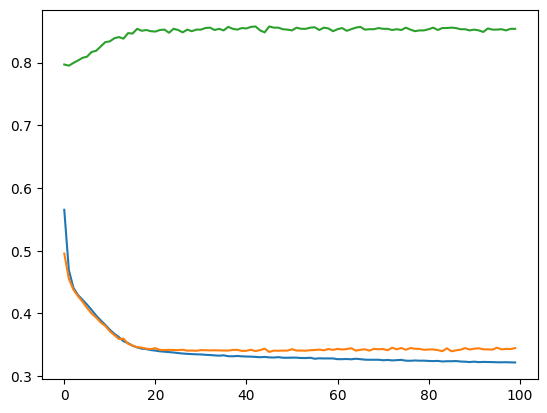

In [175]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].plot(history.history['loss'], label='Training loss')
axes[0].plot(history.history['val_loss'], label='Validation loss')
axes[0].set_title('Loss')
axes[0].set_xlabel('Epoch')
axes[0].legend()

axes[1].plot(history.history['accuracy'], label='Training accuracy')
axes[1].plot(history.history['val_accuracy'], label='Validation accuracy')
axes[1].set_title('Accuracy')
axes[1].set_xlabel('Epoch')
axes[1].legend()

plt.tight_layout()
plt.show()

## 12. Compare models and prepare inference

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score

def evaluate_model(name, y_true, probabilities, threshold=0.5):
    predictions = (probabilities >= threshold).astype(int)
    return {
        'model': name,
        'accuracy': accuracy_score(y_true, predictions),
        'precision': precision_score(y_true, predictions, zero_division=0),
        'recall': recall_score(y_true, predictions, zero_division=0),
        'f1': f1_score(y_true, predictions, zero_division=0),
        'roc_auc': roc_auc_score(y_true, probabilities)
    }

ann_probabilities = model.predict(X_test_scaled, verbose=0).ravel()

logistic_model = LogisticRegression(max_iter=1000)
logistic_model.fit(X_train_scaled, y_train)
logistic_probabilities = logistic_model.predict_proba(X_test_scaled)[:, 1]

results = [
    evaluate_model('ANN', y_test, ann_probabilities),
    evaluate_model('Logistic Regression', y_test, logistic_probabilities)
]

try:
    from xgboost import XGBClassifier
    xgb_model = XGBClassifier(
        n_estimators=300, learning_rate=0.05, max_depth=4,
        eval_metric='logloss', random_state=1, n_jobs=-1
    )
    xgb_model.fit(X_train, y_train)
    xgb_probabilities = xgb_model.predict_proba(X_test)[:, 1]
    results.append(evaluate_model('XGBoost', y_test, xgb_probabilities))
except ImportError:
    print('XGBoost is not installed. Run: %pip install xgboost')

comparison = pd.DataFrame(results).set_index('model')
comparison.sort_values('roc_auc', ascending=False)

## 13. Save the model package

In [ ]:
from pathlib import Path
import json
import joblib

artifact_dir = Path('artifacts')
artifact_dir.mkdir(exist_ok=True)

feature_columns = X.columns.tolist()
model.save(artifact_dir / 'churn_model.keras')
joblib.dump(scaler, artifact_dir / 'scaler.joblib')

with open(artifact_dir / 'feature_columns.json', 'w') as file:
    json.dump(feature_columns, file)

with open(artifact_dir / 'metadata.json', 'w') as file:
    json.dump({'threshold': 0.5}, file)

print(f'Saved model artifacts to: {artifact_dir.resolve()}')

## 14. Predict for a new customer

In [ ]:
def preprocess_customer(customer):
    row = pd.DataFrame([customer])

    row = row.drop(
        columns=['RowNumber', 'CustomerId', 'Surname'],
        errors='ignore'
    )

    row['Geography_Germany'] = (row['Geography'] == 'Germany').astype(int)
    row['Geography_Spain'] = (row['Geography'] == 'Spain').astype(int)
    row['Gender_Male'] = (row['Gender'] == 'Male').astype(int)
    row = row.drop(columns=['Geography', 'Gender'])

    row = row.reindex(columns=feature_columns, fill_value=0)
    return scaler.transform(row)

def predict_churn(customer, threshold=0.5):
    processed_customer = preprocess_customer(customer)
    probability = float(model.predict(processed_customer, verbose=0)[0, 0])

    return {
        'churn_probability': probability,
        'will_exit': int(probability >= threshold)
    }

example_customer = {
    'CreditScore': 650,
    'Geography': 'Germany',
    'Gender': 'Female',
    'Age': 45,
    'Tenure': 3,
    'Balance': 90000,
    'NumOfProducts': 1,
    'HasCrCard': 1,
    'IsActiveMember': 0,
    'EstimatedSalary': 100000
}

predict_churn(example_customer)